# 03 · External enrichment: airports and NOAA weather
Two public sources are joined to the full 6.4M-flight file (`data/external/SOURCES.md`):
* **OurAirports** - coordinates, elevation, runways for every airport in the data.
* **NOAA GHCN-Daily** - daily precipitation, snow, temperature and wind at the station nearest
  each airport (324 of 326 airports matched), turned into adverse-weather flags.

Questions: how much disruption is really weather? Which carriers and airports cope best with
bad weather (winter readiness)? Which airports are weather-exposed in which months (knowable at
booking time)?

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import prep, style
from style import INK, GREY, ACCENT, GOOD, BLUE, AMBER, PCT
style.use()
pd.set_option("display.width", 200, "display.max_columns", 60, "display.float_format", "{:.3f}".format)

f = pd.read_parquet(prep.PROCESSED / "flights_full.parquet")
air = pd.read_parquet(prep.PROCESSED / "airports.parquet")
wx = pd.read_parquet(prep.PROCESSED / "weather_daily.parquet")
print(f"{len(f):,} flights | {len(air)} airports ({air.station.notna().sum()} with weather) | {len(wx):,} airport-days of weather")

6,398,056 flights | 326 airports (324 with weather) | 117,750 airport-days of weather


## 1. Airport characteristics
Hub tier uses the FAA thresholds (share of national traffic: large >= 1%, medium 0.25-1%,
small 0.05-0.25%) applied to departures in this data.

In [2]:
dep = f.groupby("ORIGIN", observed=True).agg(departures=("disrupted", "size"), disrupted=("disrupted", "mean"),
                                             severe=("severe", "mean"), cancelled=("CANCELLED", "mean"),
                                             destinations=("DEST", "nunique"))
share = dep.departures / dep.departures.sum()
dep["hub_tier"] = pd.cut(share, [-1, .0005, .0025, .01, 1], labels=["non-hub", "small", "medium", "large"])
dom = f.groupby(["ORIGIN", "CARRIER"], observed=True).size().groupby(level=0).apply(lambda s: s.max() / s.sum())
dep["dominant_carrier_share"] = dom.values
dep["dominant_carrier"] = f.groupby(["ORIGIN", "CARRIER"], observed=True).size().groupby(level=0).idxmax().str[1].values
dep["regional_share"] = f.groupby("ORIGIN", observed=True).regional.mean()
air = air.merge(dep.reset_index().rename(columns={"ORIGIN": "airport"}), on="airport", how="left")
air.to_parquet(prep.PROCESSED / "airports_enriched.parquet", index=False)
air.sort_values("departures", ascending=False).head(12)[["airport", "name", "hub_tier", "departures", "destinations", "runways", "longest_runway_ft", "dominant_carrier", "dominant_carrier_share", "disrupted", "station_km"]]

C:\Users\anair\AppData\Local\Temp\ipykernel_21524\240433882.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dom = f.groupby(["ORIGIN", "CARRIER"], observed=True).size().groupby(level=0).apply(lambda s: s.max() / s.sum())


C:\Users\anair\AppData\Local\Temp\ipykernel_21524\240433882.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dep["dominant_carrier"] = f.groupby(["ORIGIN", "CARRIER"], observed=True).size().groupby(level=0).idxmax().str[1].values


,airport,name,hub_tier,departures,destinations,runways,longest_runway_ft,dominant_carrier,dominant_carrier_share,disrupted,station_km
13,ORD,Chicago O'Hare International Airport,large,317040,180,8,13000.000,UA,0.301,0.279,3.000
188,DFW,Dallas Fort Worth International Airport,large,300409,184,7,13401.000,AA,0.545,0.311,1.500
189,DEN,Denver International Airport,large,295063,181,6,16000.000,UA,0.358,0.265,2.100
209,ATL,Hartsfield Jackson Atlanta International Airport,large,290721,149,5,12390.000,DL,0.816,0.244,1.500
168,CLT,Charlotte Douglas International Airport,large,189205,136,3,10000.000,AA,0.623,0.261,1.400
6,PHX,Phoenix Sky Harbor International Airport,large,187906,111,3,11489.000,WN,0.363,0.204,0.900
165,LAX,Los Angeles International Airport,large,175460,97,4,12894.000,OO,0.231,0.179,2.000
132,SEA,Seattle–Tacoma International Airport,large,161138,91,3,11901.000,AS,0.469,0.229,0.500
269,LAS,Harry Reid International Airport,large,146682,87,4,14835.000,WN,0.592,0.222,1.600
192,DCA,Ronald Reagan Washington National Airport,large,141481,104,3,7169.000,OH,0.295,0.302,0.600


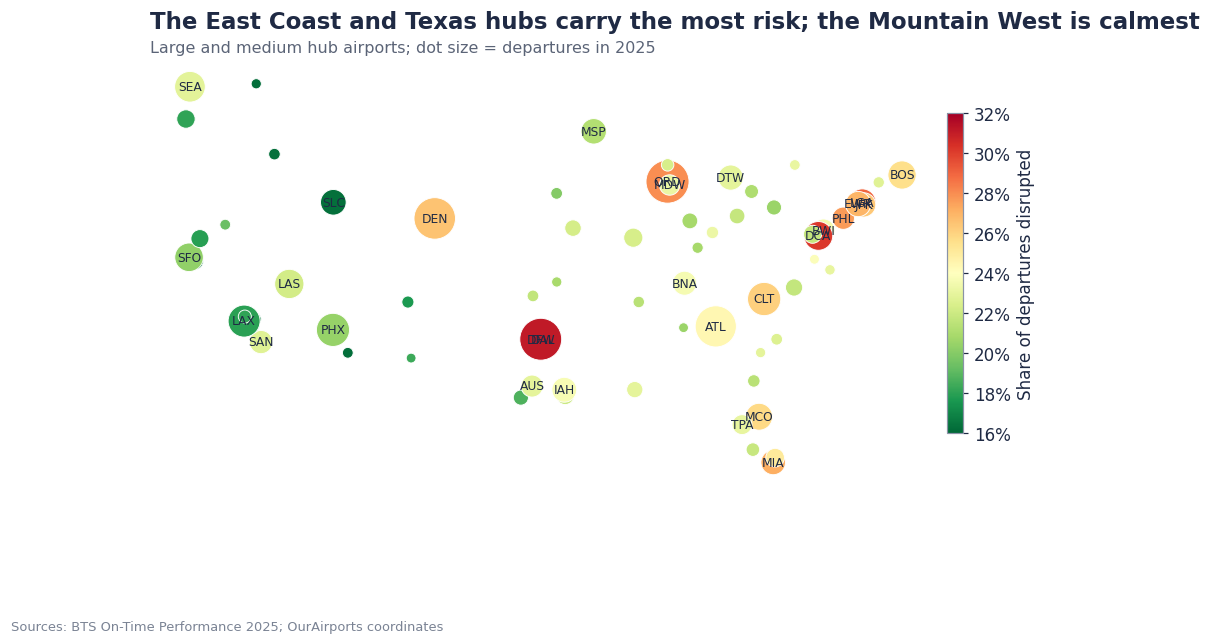

In [3]:
big = air[air.hub_tier.isin(["large", "medium"])].dropna(subset=["lat"])
lower48 = big[(big.lon > -130) & (big.lat > 23)]
fig, ax = plt.subplots(figsize=(11, 6.3))
sc = ax.scatter(lower48.lon, lower48.lat, s=lower48.departures / 400, c=lower48.disrupted, cmap="RdYlGn_r",
                vmin=.16, vmax=.32, edgecolor="white", lw=.6, zorder=3)
for r in lower48[lower48.hub_tier == "large"].itertuples():
    ax.annotate(r.airport, (r.lon, r.lat), fontsize=8, ha="center", va="center", color=INK, zorder=4)
ax.set_aspect(1.25); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(sc, ax=ax, shrink=.6, pad=.01); cb.ax.yaxis.set_major_formatter(PCT); cb.set_label("Share of departures disrupted")
style.titled(ax, "The East Coast and Texas hubs carry the most risk; the Mountain West is calmest",
             "Large and medium hub airports; dot size = departures in 2025")
style.save(fig, "09_airport_map", "Sources: BTS On-Time Performance 2025; OurAirports coordinates");

## 2. Join the weather to each flight (origin and destination, same calendar day)

In [4]:
flags = ["wx_snow", "wx_freezing", "wx_heavy_rain", "wx_thunder", "wx_fog", "wx_wind", "wx_adverse", "wx_winter"]
w = wx[["airport", "date", *flags]]
fo = f.merge(w.rename(columns={"airport": "ORIGIN", "date": "FL_DATE"}).rename(columns={c: "o_" + c for c in flags}), on=["ORIGIN", "FL_DATE"], how="left")
fo = fo.merge(w.rename(columns={"airport": "DEST", "date": "FL_DATE"}).rename(columns={c: "d_" + c for c in flags}), on=["DEST", "FL_DATE"], how="left")
matched = fo.o_wx_adverse.notna() & fo.d_wx_adverse.notna()
print(f"flights with weather at both ends: {matched.mean():.1%}")
fo = fo[matched].copy()
for c in flags:
    fo["e_" + c] = ((fo["o_" + c] == 1) | (fo["d_" + c] == 1)).astype("int8")   # either end
fo[["FL_DATE", "ORIGIN", "DEST", "o_wx_adverse", "d_wx_adverse", "e_wx_adverse"]].to_parquet(prep.PROCESSED / "flight_weather_flags.parquet", index=False)

flights with weather at both ends: 98.9%


## 3. How much disruption is really weather?
BTS attributes only ~7% of delay minutes to "weather", but air-traffic (NAS) delays and
cascading late-aircraft delays are often weather-driven too. Compare flights on days with
adverse weather at either end against clear days.

In [5]:
rows = []
for c, lab in [("e_wx_adverse", "Any adverse weather"), ("e_wx_thunder", "Thunderstorms"), ("e_wx_snow", "Snow"),
               ("e_wx_freezing", "Freezing precipitation"), ("e_wx_heavy_rain", "Heavy rain (0.5in+)"), ("e_wx_fog", "Heavy fog"), ("e_wx_wind", "High wind")]:
    g = fo.groupby(c)[["disrupted", "severe", "CANCELLED"]].mean()
    rows.append([lab, (fo[c] == 1).mean(), g.loc[1, "disrupted"], g.loc[0, "disrupted"], g.loc[1, "severe"], g.loc[0, "severe"], g.loc[1, "CANCELLED"], g.loc[0, "CANCELLED"]])
wt = pd.DataFrame(rows, columns=["condition", "share_of_flights", "disrupted_on", "disrupted_off", "severe_on", "severe_off", "cancelled_on", "cancelled_off"]).set_index("condition")
wt["uplift"] = wt.disrupted_on / wt.disrupted_off
adverse = fo.e_wx_adverse == 1
excess = ((fo[adverse].disrupted.mean() - fo[~adverse].disrupted.mean()) * adverse.sum()) / fo.disrupted.sum()
wt.to_csv(prep.TABLES / "weather_conditions.csv")
print(f"Flights on adverse-weather days: {adverse.mean():.1%}. Excess disruptions on those days = {excess:.1%} of all disruptions.")
wt

Flights on adverse-weather days: 36.2%. Excess disruptions on those days = 23.4% of all disruptions.


,share_of_flights,disrupted_on,disrupted_off,severe_on,severe_off,cancelled_on,cancelled_off,uplift
condition,,,,,,,,
Any adverse weather,0.362,0.332,0.180,0.160,0.061,0.030,0.006,1.842
Thunderstorms,0.215,0.348,0.204,0.172,0.076,0.028,0.011,1.706
Snow,0.029,0.495,0.227,0.280,0.091,0.096,0.012,2.178
Freezing precipitation,0.048,0.415,0.226,0.221,0.091,0.071,0.012,1.834
Heavy rain (0.5in+),0.100,0.382,0.219,0.200,0.085,0.040,0.012,1.746
Heavy fog,0.069,0.326,0.228,0.164,0.092,0.037,0.013,1.428
High wind,0.058,0.343,0.229,0.171,0.092,0.031,0.014,1.500


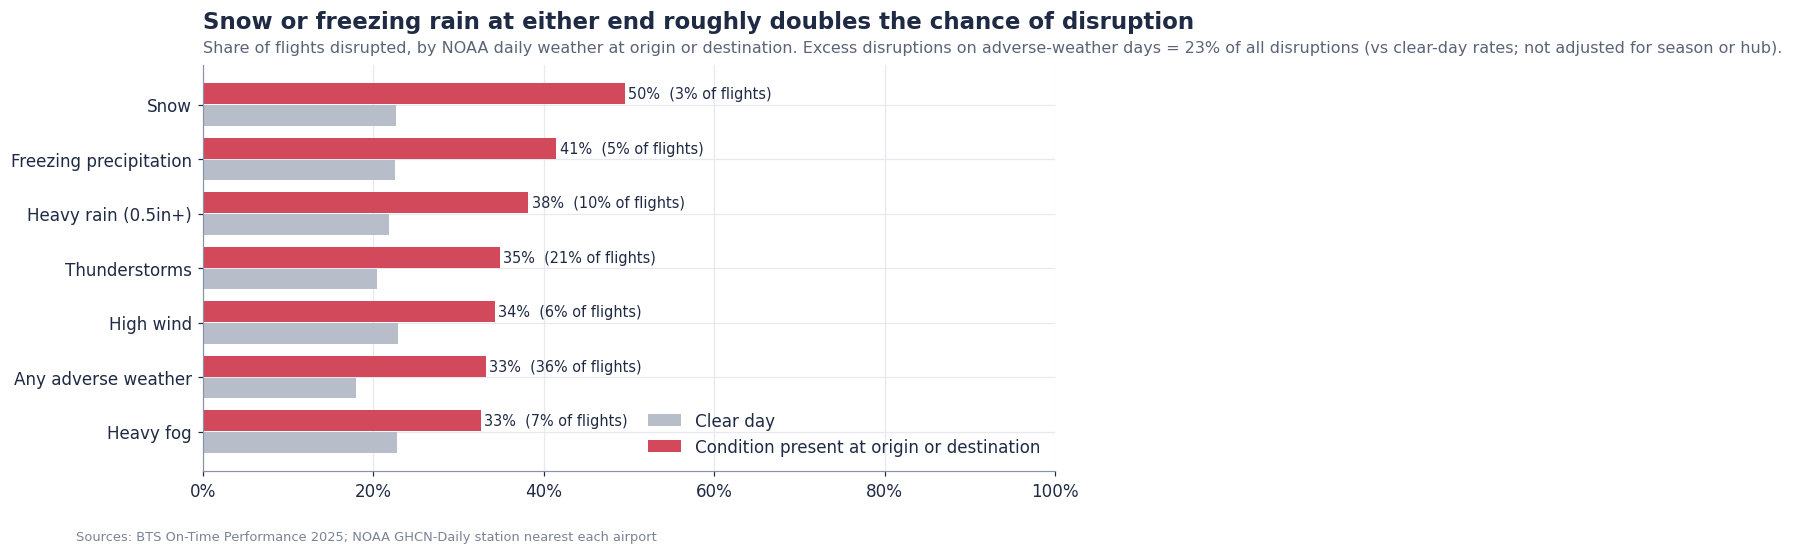

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
o = wt.sort_values("disrupted_on")
y = np.arange(len(o))
ax.barh(y, o.disrupted_off, color=GREY, height=.38, label="Clear day")
ax.barh(y + .4, o.disrupted_on, color=ACCENT, height=.38, label="Condition present at origin or destination")
for i, (a, b, s) in enumerate(zip(o.disrupted_off, o.disrupted_on, o.share_of_flights)):
    ax.text(b + .004, i + .4, f"{b:.0%}  ({s:.0%} of flights)", va="center", fontsize=9.5)
ax.set_yticks(y + .2); ax.set_yticklabels(o.index); ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, 1.0); ax.legend(loc="lower right")
style.titled(ax, "Snow or freezing rain at either end roughly doubles the chance of disruption",
             f"Share of flights disrupted, by NOAA daily weather at origin or destination. Excess disruptions on adverse-weather days = {excess:.0%} of all disruptions (vs clear-day rates; not adjusted for season or hub).")
style.save(fig, "10_weather_conditions", "Sources: BTS On-Time Performance 2025; NOAA GHCN-Daily station nearest each airport");

## 4. Carrier resilience: who copes best when the weather turns?

,clear,adverse,uplift_pts
CARRIER,,,
Delta,0.153,0.295,0.142
Alaska,0.224,0.295,0.071
Southwest,0.175,0.312,0.138
United,0.167,0.316,0.149
SkyWest,0.165,0.332,0.167
Envoy,0.156,0.352,0.196
Republic,0.174,0.353,0.179
JetBlue,0.221,0.357,0.136
American,0.214,0.376,0.162


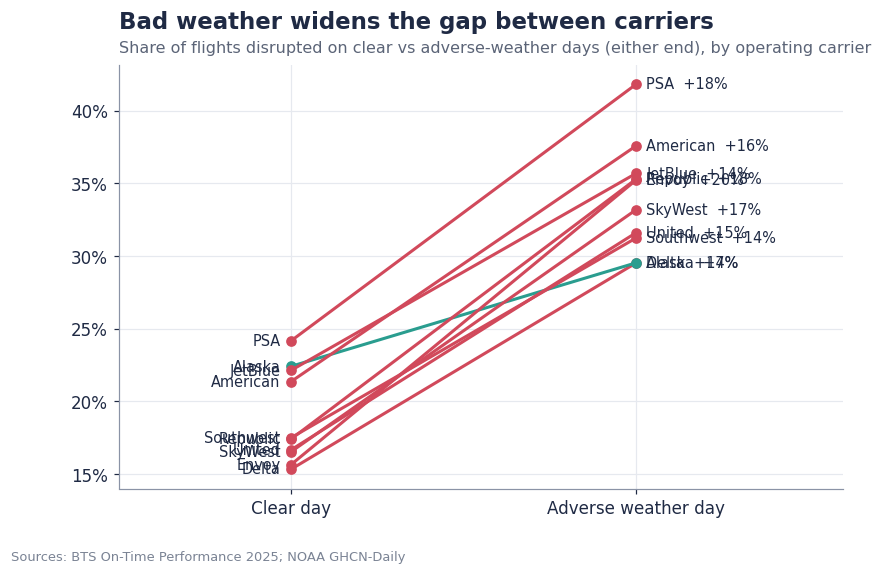

In [7]:
cr = fo.groupby(["carrier_name" if "carrier_name" in fo else "CARRIER", "e_wx_adverse"], observed=True).disrupted.mean().unstack()
cr.columns = ["clear", "adverse"]; cr["uplift_pts"] = cr.adverse - cr.clear
cr = cr.sort_values("adverse"); cr.index = cr.index.map(prep.CARRIER_NAMES)
cr.to_csv(prep.TABLES / "carrier_weather_resilience.csv")
fig, ax = plt.subplots(figsize=(8.5, 5))
for i, (n, r) in enumerate(cr.iterrows()):
    ax.plot([0, 1], [r.clear, r.adverse], color=ACCENT if r.uplift_pts > .11 else (GOOD if r.uplift_pts < .085 else GREY), lw=2, marker="o")
    ax.text(1.03, r.adverse, f"{n}  +{r.uplift_pts:.0%}", va="center", fontsize=9.5)
    ax.text(-.03, r.clear, n, va="center", ha="right", fontsize=9.5)
ax.set_xlim(-.5, 1.6); ax.set_xticks([0, 1]); ax.set_xticklabels(["Clear day", "Adverse weather day"]); ax.yaxis.set_major_formatter(PCT)
style.titled(ax, "Bad weather widens the gap between carriers", "Share of flights disrupted on clear vs adverse-weather days (either end), by operating carrier")
style.save(fig, "11_carrier_weather_resilience", "Sources: BTS On-Time Performance 2025; NOAA GHCN-Daily");
cr

## 5. Winter readiness ("ice-proofing") by airport
No public list of de-icing capacity exists, so readiness is measured by **outcome**: how much
a hub's departures degrade on snow / freezing days compared with its own clear days.

,name,hub_tier,winter_days_pct,disrupted_clear,disrupted_winter,uplift_pts,cancelled_winter
GEG,Spokane International Airport,medium,0.077,0.155,0.258,0.103,0.007
SEA,Seattle–Tacoma International Airport,large,0.011,0.228,0.338,0.111,0.029
AUS,Austin Bergstrom International Airport,large,0.011,0.228,0.344,0.117,0.065
BOI,Boise Air Terminal/Gowen Field,medium,0.044,0.158,0.275,0.117,0.010
ANC,Ted Stevens Anchorage International Airport,medium,0.056,0.164,0.297,0.133,0.012
BDL,Bradley International Airport,medium,0.093,0.214,0.357,0.143,0.033
RDU,Raleigh-Durham International Airport,medium,0.022,0.214,0.371,0.156,0.109
SAT,San Antonio International Airport,medium,0.011,0.185,0.345,0.160,0.170
BWI,Baltimore/Washington International Thurgood Ma...,large,0.055,0.227,0.388,0.161,0.053
RNO,Reno Tahoe International Airport,medium,0.019,0.190,0.355,0.165,0.016


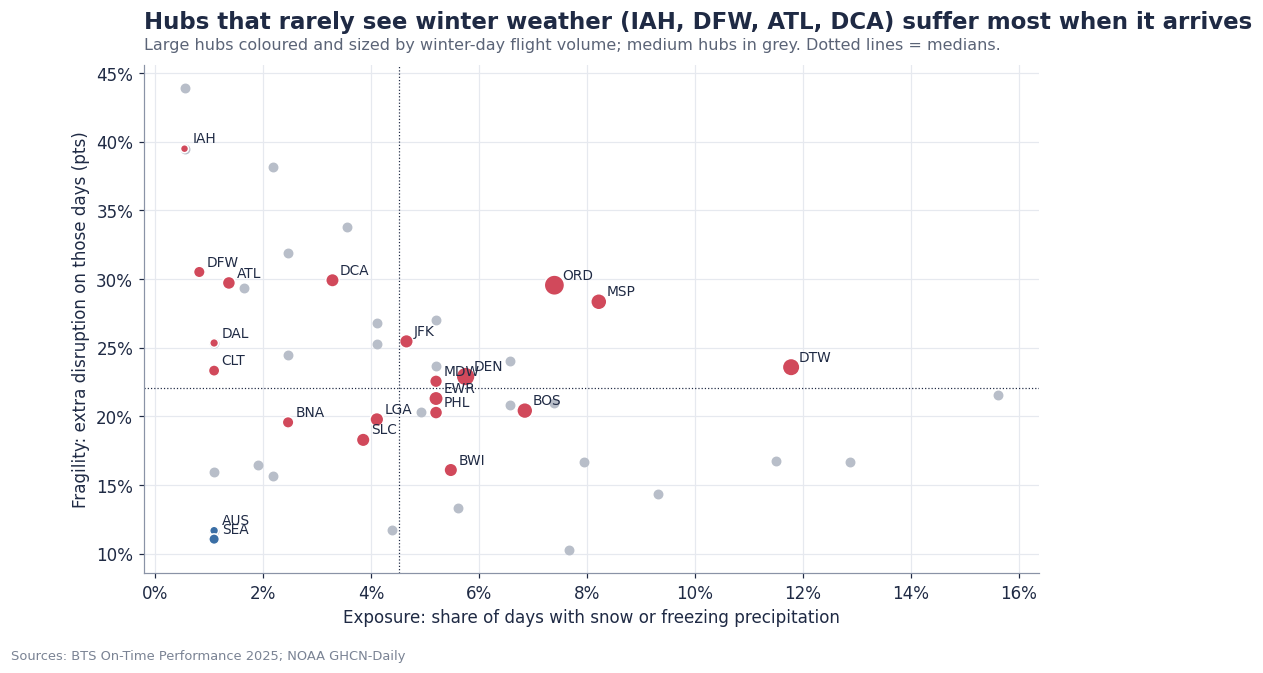

In [8]:
hubs = air[air.hub_tier.isin(["large", "medium"])].airport.tolist()
win = fo[fo.ORIGIN.isin(hubs)].groupby(["ORIGIN", "o_wx_winter"], observed=True).agg(n=("disrupted", "size"), disrupted=("disrupted", "mean"), cancelled=("CANCELLED", "mean")).unstack()
wr = pd.DataFrame({"winter_days_pct": wx[wx.airport.isin(hubs)].groupby("airport").wx_winter.mean(),
                   "n_winter_flights": win[("n", 1)], "disrupted_clear": win[("disrupted", 0)], "disrupted_winter": win[("disrupted", 1)],
                   "cancelled_clear": win[("cancelled", 0)], "cancelled_winter": win[("cancelled", 1)]}).dropna()
wr = wr[wr.n_winter_flights >= 300]
wr["uplift_pts"] = wr.disrupted_winter - wr.disrupted_clear
wr["cancel_uplift_pts"] = wr.cancelled_winter - wr.cancelled_clear
wr = wr.merge(air.set_index("airport")[["name", "hub_tier"]], left_index=True, right_index=True)
wr.to_csv(prep.TABLES / "winter_readiness.csv")
fig, ax = plt.subplots(figsize=(10.5, 6))
big = wr[wr.hub_tier == "large"]
ax.scatter(wr.winter_days_pct, wr.uplift_pts, s=30, color=GREY)
ax.scatter(big.winter_days_pct, big.uplift_pts, s=np.sqrt(big.n_winter_flights) * 1.2, color=[ACCENT if u > .15 else (GOOD if u < .08 else BLUE) for u in big.uplift_pts], edgecolor="white")
for r in big.itertuples():
    ax.annotate(r.Index, (r.winter_days_pct, r.uplift_pts), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.axhline(wr.uplift_pts.median(), color=INK, lw=.8, ls=":"); ax.axvline(wr.winter_days_pct.median(), color=INK, lw=.8, ls=":")
ax.xaxis.set_major_formatter(PCT); ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Exposure: share of days with snow or freezing precipitation"); ax.set_ylabel("Fragility: extra disruption on those days (pts)")
style.titled(ax, "Hubs that rarely see winter weather (IAH, DFW, ATL, DCA) suffer most when it arrives",
             "Large hubs coloured and sized by winter-day flight volume; medium hubs in grey. Dotted lines = medians.")
style.save(fig, "12_winter_readiness", "Sources: BTS On-Time Performance 2025; NOAA GHCN-Daily");
wr.sort_values("uplift_pts")[["name", "hub_tier", "winter_days_pct", "disrupted_clear", "disrupted_winter", "uplift_pts", "cancelled_winter"]]

## 6. Weather risk you can know at booking time: adverse-day frequency by airport and month

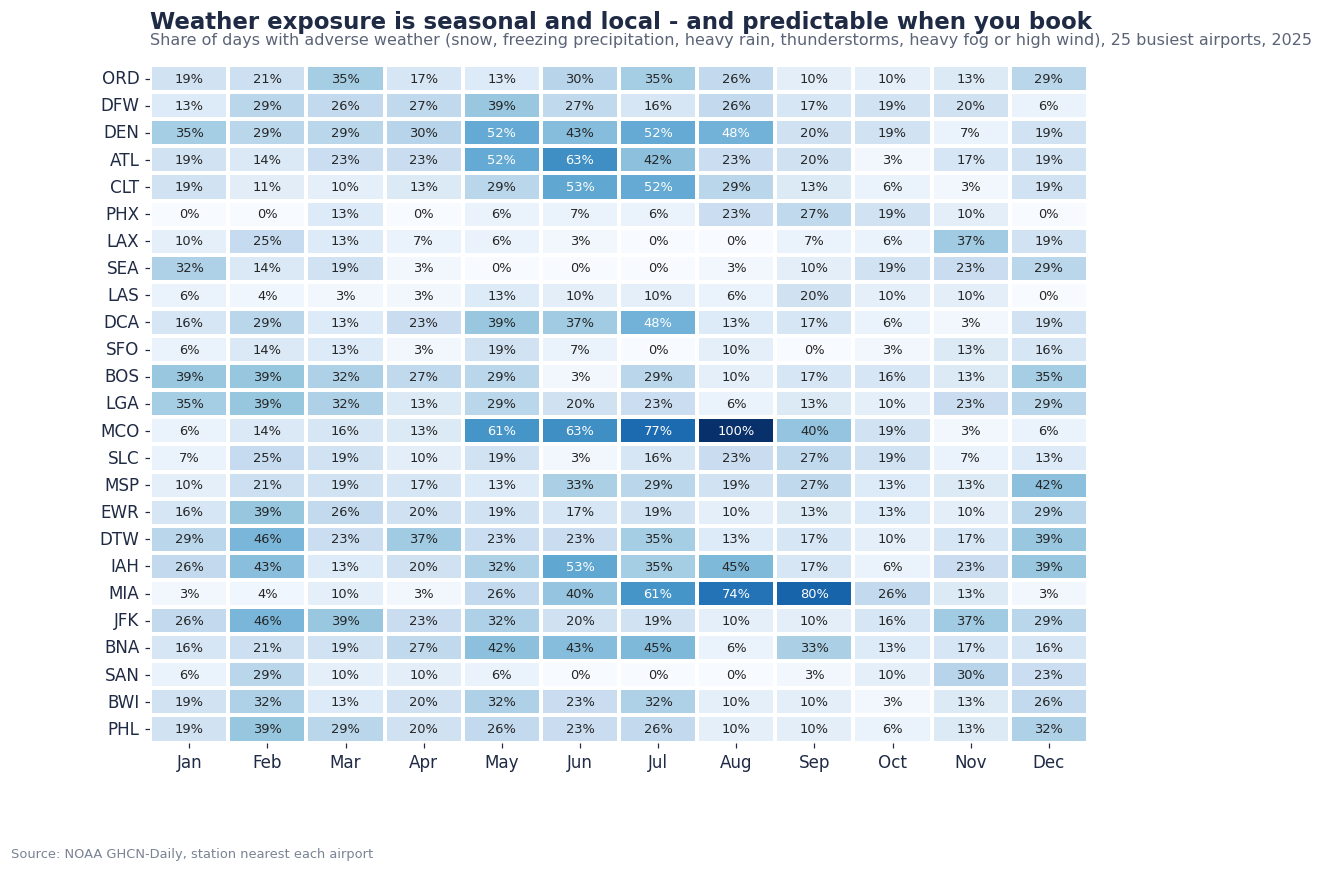

In [9]:
clim = wx.assign(month=wx.date.dt.month).groupby(["airport", "month"])[["wx_adverse", "wx_winter", "wx_thunder"]].mean()
clim.columns = ["p_adverse", "p_winter", "p_thunder"]
clim.reset_index().to_parquet(prep.PROCESSED / "weather_climatology.parquet", index=False)
top = air.sort_values("departures", ascending=False).airport.head(25)
hm = clim.p_adverse.unstack().loc[top]
hm.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(hm, annot=True, fmt=".0%", cmap="Blues", cbar=False, linewidths=1.5, linecolor="white", ax=ax, annot_kws={"fontsize": 8.5})
ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
style.titled(ax, "Weather exposure is seasonal and local - and predictable when you book",
             "Share of days with adverse weather (snow, freezing precipitation, heavy rain, thunderstorms, heavy fog or high wind), 25 busiest airports, 2025")
style.save(fig, "13_weather_climatology", "Source: NOAA GHCN-Daily, station nearest each airport");

## 7. Sanity check: the January 2025 winter storms

In [10]:
chk = wx[(wx.date.between("2025-01-05", "2025-01-10")) & wx.airport.isin(["ATL", "DFW", "CLT", "IAH", "DCA", "ORD", "DEN", "BOS"])]
chk.pivot_table(index="airport", columns=chk.date.dt.strftime("%b %d"), values="wx_winter", aggfunc="max").astype(int)

date,Jan 05,Jan 06,Jan 07,Jan 08,Jan 09,Jan 10
airport,,,,,,
ATL,0,1,0,0,0,1
BOS,0,0,0,0,0,0
CLT,0,1,0,0,0,1
DCA,0,1,0,0,0,0
DEN,0,1,1,0,1,0
DFW,0,0,0,0,1,0
IAH,0,0,0,0,0,0
ORD,1,1,0,0,0,1


## Takeaways
* Flights touching an airport with adverse weather are ~1.6x as likely to be disrupted; on snow
  or freezing days the risk roughly doubles. Weather explains a much larger share of disruption
  than the ~7% the airlines' "weather" code suggests.
* Carriers differ in resilience: the gap between the best and worst carrier widens on bad days.
* Southern hubs that rarely see winter weather (IAH, DFW, ATL, DCA) add ~30 points of disruption
  when it arrives; frequently-snowed hubs (DTW, DEN, BWI, BOS) add ~16-24. This feeds the
  connecting-hub advice for December-February.
* Adverse-day frequency by airport and month is stable enough to be a booking-time feature.